(440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185
[ 1  2  3  4  5  6  7  8  9 10] e 1 | [880.0000000000001, 434.88002232384395, 274.17120285837404, 195.66099155249032, 168.151325680287, 134.36889821093604, 116.37489365378372, 102.56384145408023, 92.11751363257281, 82.95229579311636] e 880.0000000000001
 [ 1  2  3  4  5  6  7  8  9 10] e 10 | [880.0000000000001, 434.88002232384395, 274.17120285837404, 195.66099155249032, 168.151325680287, 134.36889821093604, 116.37489365378372, 102.56384145408023, 92.11751363257281, 82.95229579311636] e 82.95229579311636
P1: [  

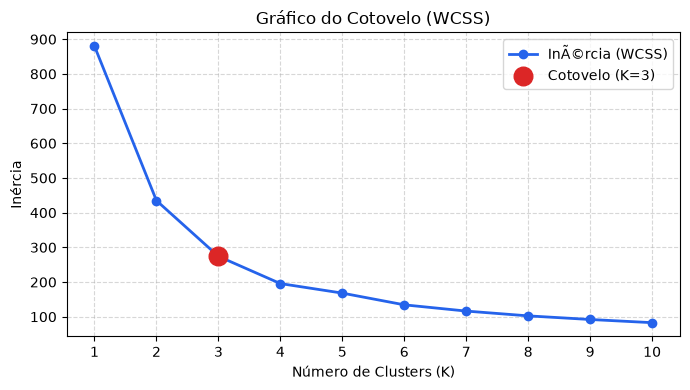

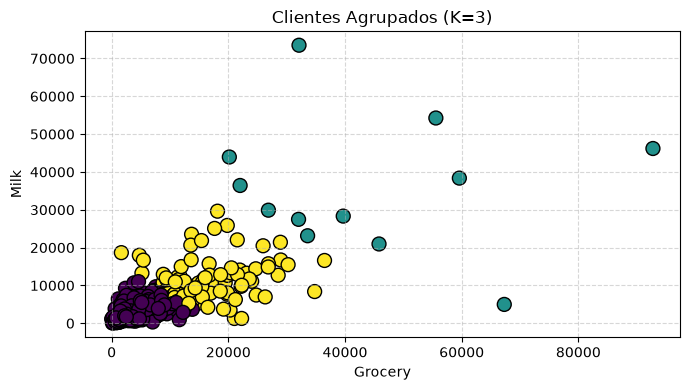

In [ ]:
# ==============================================================================
# 0. IMPORTS
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# ==============================================================================
# 1. FUNÇÃO ORIGINAL
# ==============================================================================
def cross2d(x, y):
    return x[..., 0] * y[..., 1] - x[..., 1] * y[..., 0]

def get_k_otimo(X, k_max=10):
    # normalização
    X_std = StandardScaler().fit_transform(X)
    # Numpy - Biblioteca para processamento de dados e operações númericas no python
    ks = np.arange(1, k_max + 1)
    # Aplicando a clusterização por K-Means
    w = [KMeans(k, n_init='auto', random_state=42).fit(X_std).inertia_ for k in ks]
    # print(f"{ks} e {ks[0]} | {w} e {w[0]}\n {ks} e {ks[-1]} | {w} e {w[-1]}") #testes para ver os valores
    p1, p2, pts = np.array([ks[0], w[0]]), np.array([ks[-1], w[-1]]), np.column_stack([ks, w])
    # print(f"P1: {p1}\nP2: {p2}\nPTS: {pts}") #testes para ver os valores
    # Calcula o produto vetorial entre 2 vetores
    # //TODO - Estou alterando como a biblioteca do numpy pede para fazer pois o .cross() não trabalha mais com 2 vetores somente (vetores bidimensionais) somente com vetores tridimenssionais 
    # link: https://numpy.org/doc/2.2/reference/generated/numpy.cross.html#numpy-cross
    # return ks[np.argmax(np.abs(np.cross(p2 - p1, pts - p1)))]
    return ks[np.argmax(np.abs(cross2d(p2 - p1, pts - p1)))]

# ==============================================================================
# 2. FUNÃ‡ÃƒO PARA PLOTAR O COTOVELO
# ==============================================================================
def plotar_cotovelo(X, k_max=10):
    X_std = StandardScaler().fit_transform(X)
    ks = np.arange(1, k_max + 1)
    w = [KMeans(k, n_init='auto', random_state=42).fit(X_std).inertia_ for k in ks]
    k_otimo = get_k_otimo(X, k_max)

    plt.figure(figsize=(7, 4))
    plt.plot(ks, w, 'o-', color='#2563eb', linewidth=2, label='InÃ©rcia (WCSS)')
    plt.scatter(k_otimo, w[k_otimo - 1], color='#dc2626', s=180, zorder=5, label=f'Cotovelo (K={k_otimo})')
    plt.title('Gráfico do Cotovelo (WCSS)')
    plt.xlabel('Número de Clusters (K)')
    plt.ylabel('Inércia')
    plt.xticks(ks)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. FUNÃ‡ÃƒO PARA PLOTAR OS DADOS (COM OS CLUSTERS)
# ==============================================================================
def plotar_dataframe(df, k=None):
    plt.figure(figsize=(7, 4))
    col_x, col_y = df.columns[0], df.columns[1]

    if k:
        X_std = StandardScaler().fit_transform(df)
        clusters = KMeans(k, n_init='auto', random_state=42).fit_predict(X_std)
        plt.scatter(df[col_x], df[col_y], c=clusters, cmap='viridis', s=100, edgecolors='k')
        plt.title(f'Clientes Agrupados (K={k})')
    else:
        plt.scatter(df[col_x], df[col_y], color='#2563eb', s=100, edgecolors='k')
        plt.title('DistribuiÃ§Ã£o dos Dados do DataFrame')

    plt.xlabel(col_x)
    plt.ylabel(col_y)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 4. DATASET â€” CLIENTES ATACADISTAS (B2B) â€” UCI
# ==============================================================================
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
df = pd.read_csv(url)

print(df.shape)   # (440, 8)
print(df.head())

# Recorte: Mercearia vs. LaticÃ­nios
X = df[['Grocery', 'Milk']]

k = get_k_otimo(X)
print(f"\n['Grocery', 'Milk'] -> Kmeans: {k}")

plotar_cotovelo(X)
plotar_dataframe(X, k=k)